In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("bayesian_stats_course_tools.light")
import scipy.stats
import emcee
from pathlib import Path
from emcee.autocorr import integrated_time
from scipy.signal import lfilter
import arviz

plt.rcParams['text.usetex'] = True # comment out if you don't have latex installed. May cause errors downstream in titles, etc.
figdir = Path('./')
savefigs = True

# Exercise 1: Autocorrelation

## Intro

In [2]:
Nsamples = 4000
# Gaussian random samples
iid_samples = np.random.randn(Nsamples)

### Create correlated samples

The (normalized) autocorrelation function is given by:

$$\rho(|t_i - t_j|) = e^{{-2|t_i - t_j| / \tau}}$$

where $\tau$ here is the $\tau$ we defined in the lecture notes. Below, we generate correlated samples with this autocorrelation function. There are a few ways to do this; I've taken a shortcut with an "autoregressive" model to make the generation of fake data fast. Use this code as a blackbox for now to generate correleted samples:
```python
tau_autocorr = 10


def ar1(N, tau, rng):
    phi = np.exp(-2/tau)
    w = rng.standard_normal(N)
    w[0] /= np.sqrt(1 - phi**2)          # stationary start
    return lfilter([np.sqrt(1 - phi**2)], [1, -phi], w)

correlated_samples = ar1(Nsamples, tau_autocorr, rng)
```

In [3]:
tau_autocorr = 10

rng = np.random.default_rng(0)

# auto-regressive process to produce correlated samples
# according to an exponential autocorrelation function
# this is much faster than creating a toepliz covariance matrix
# with rho = exp(-2 * lag / tau) and using np.random.multivariate_normal
def ar1(N, tau, rng, nchains=1):
    phi = np.exp(-2/tau)
    w = rng.standard_normal((N, nchains))
    w[0] /= np.sqrt(1 - phi**2)          # stationary start
    return lfilter([np.sqrt(1 - phi**2)], [1, -phi], w, axis=0)

correlated_samples = ar1(Nsamples, tau_autocorr, rng)

tau_estimated = emcee.autocorr.integrated_time(correlated_samples)
print(f'estimated tau: {tau_estimated}, true tau: {tau_autocorr}')

estimated tau: [11.46087968], true tau: 10


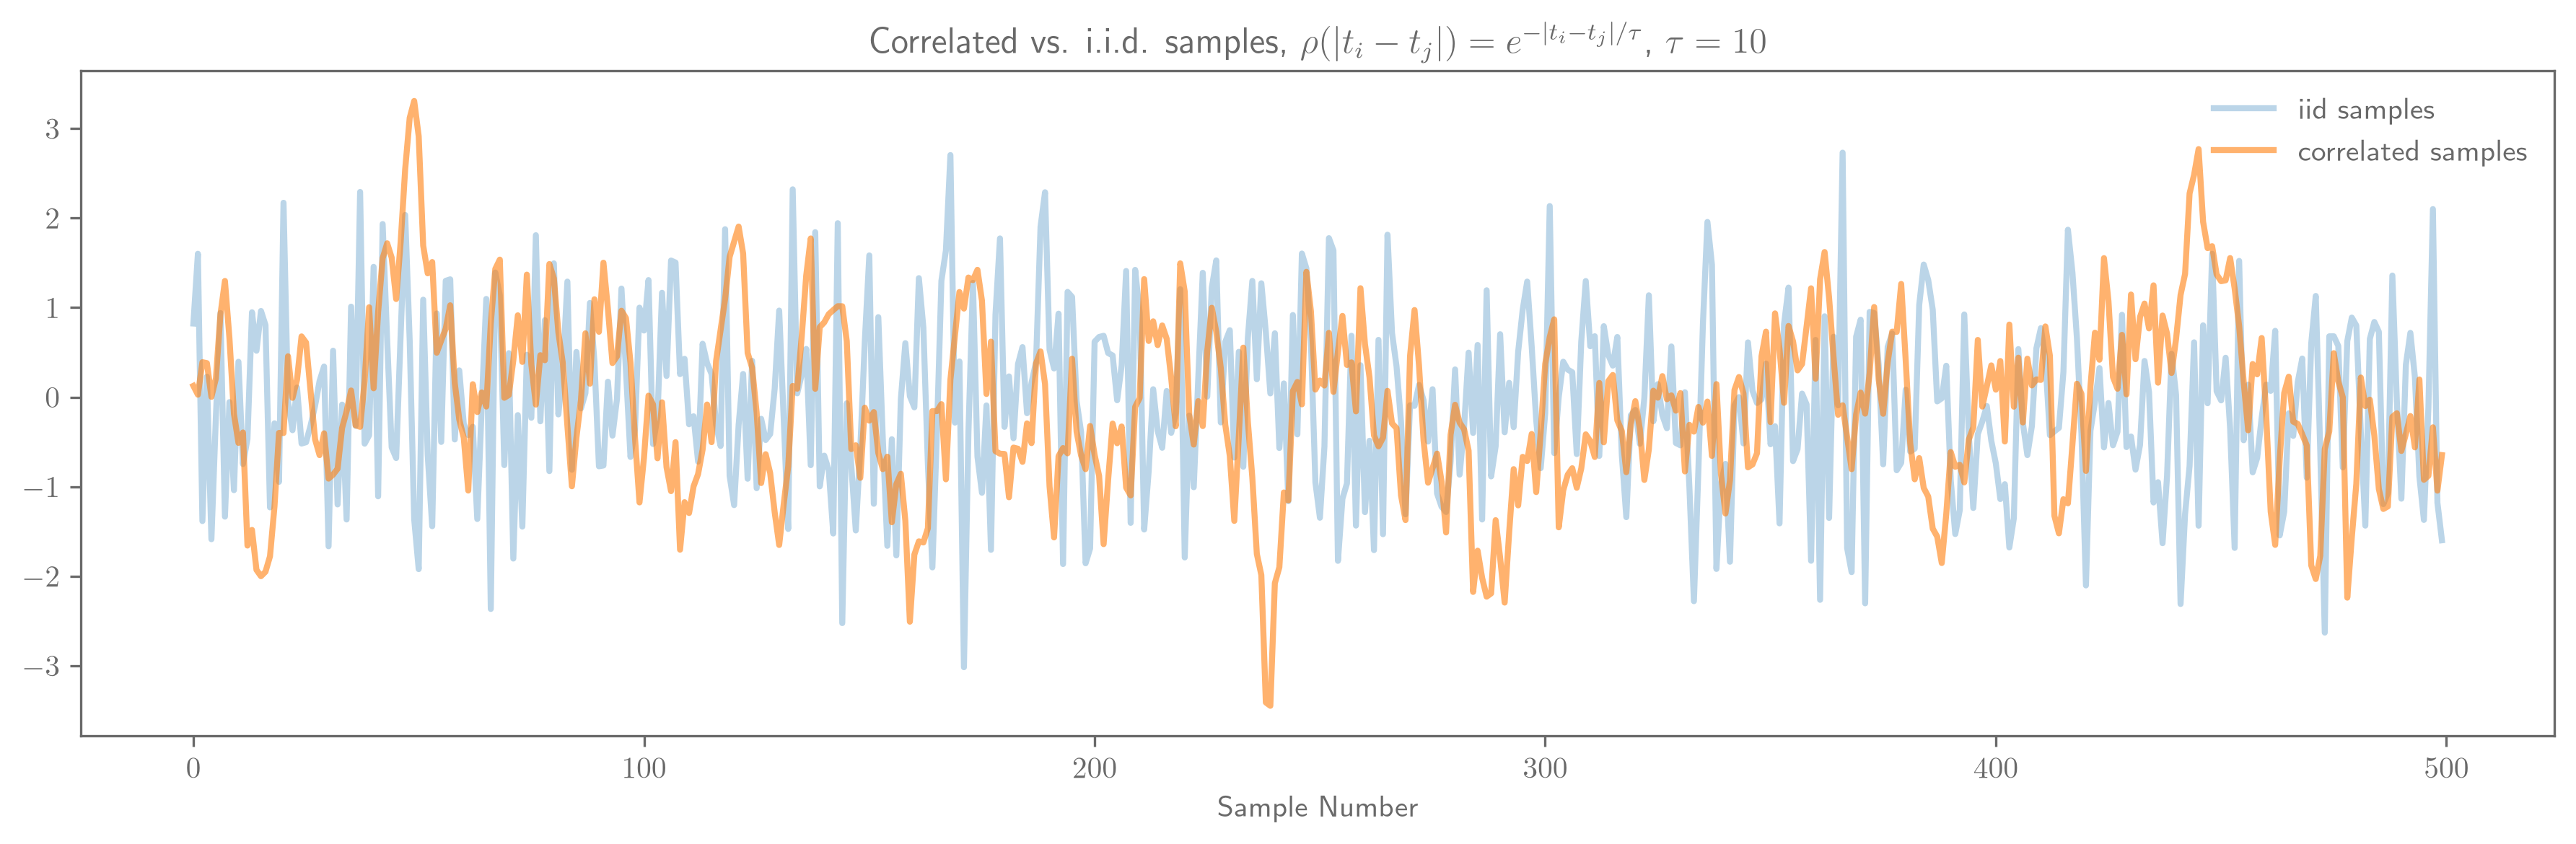

In [4]:
plt.figure(figsize=(12, 4))
# may cause an error if you don't have latex installed. Can comment out title in that case.
plt.title(f"Correlated vs. i.i.d. samples, $\\rho(|t_i - t_j|) = e^{{-|t_i - t_j| / \\tau}}$, $\\tau={tau_autocorr}$")
plt.plot(iid_samples[:tau_autocorr*50], lw=2, label='iid samples', alpha=0.3)
plt.plot(correlated_samples[:tau_autocorr*50], lw=2, label='correlated samples', alpha=0.6)
plt.legend()
plt.xlabel("Sample Number")
plt.tight_layout()
if savefigs:
    plt.savefig(figdir / "correlated_samples_example.pdf")
plt.show()

### Gelman Rubin calculator

In [5]:
def gelman_rubin(x):
    n, m = x.shape
    chain_means = x.mean(axis=0)
    chain_vars = x.var(axis=0, ddof=1)

    # mean of variances
    W = chain_vars.mean()

    # variances of means
    B = n * chain_means.var(ddof=1)

    # construct the statistic
    var_hat = (n - 1) / n * W + B / n
    return np.sqrt(var_hat / W)

# split our chain up into 10 separate chains
split_chains = 10
print('Rhat statistic:', gelman_rubin(iid_samples.reshape((split_chains, Nsamples // split_chains)).T))

# NOTE: Do not pass emcee chains that come from different walkers and calculate an Rhat on that -- those chains are correlated with each other
# and you will not get a good estimate of convergence. This is mentioned here: https://emcee.readthedocs.io/en/stable/tutorials/autocorr/

Rhat statistic: 0.9998012428207298


### Look at autocorrelation times

In [6]:
# estimate autocorrelation times using emcee's method many times for many
# realizations. look at variance of this quantity. 
taus = [integrated_time(ar1(Nsamples, tau_autocorr, rng), quiet=True, tol=0)[0] for _ in range(1000)]

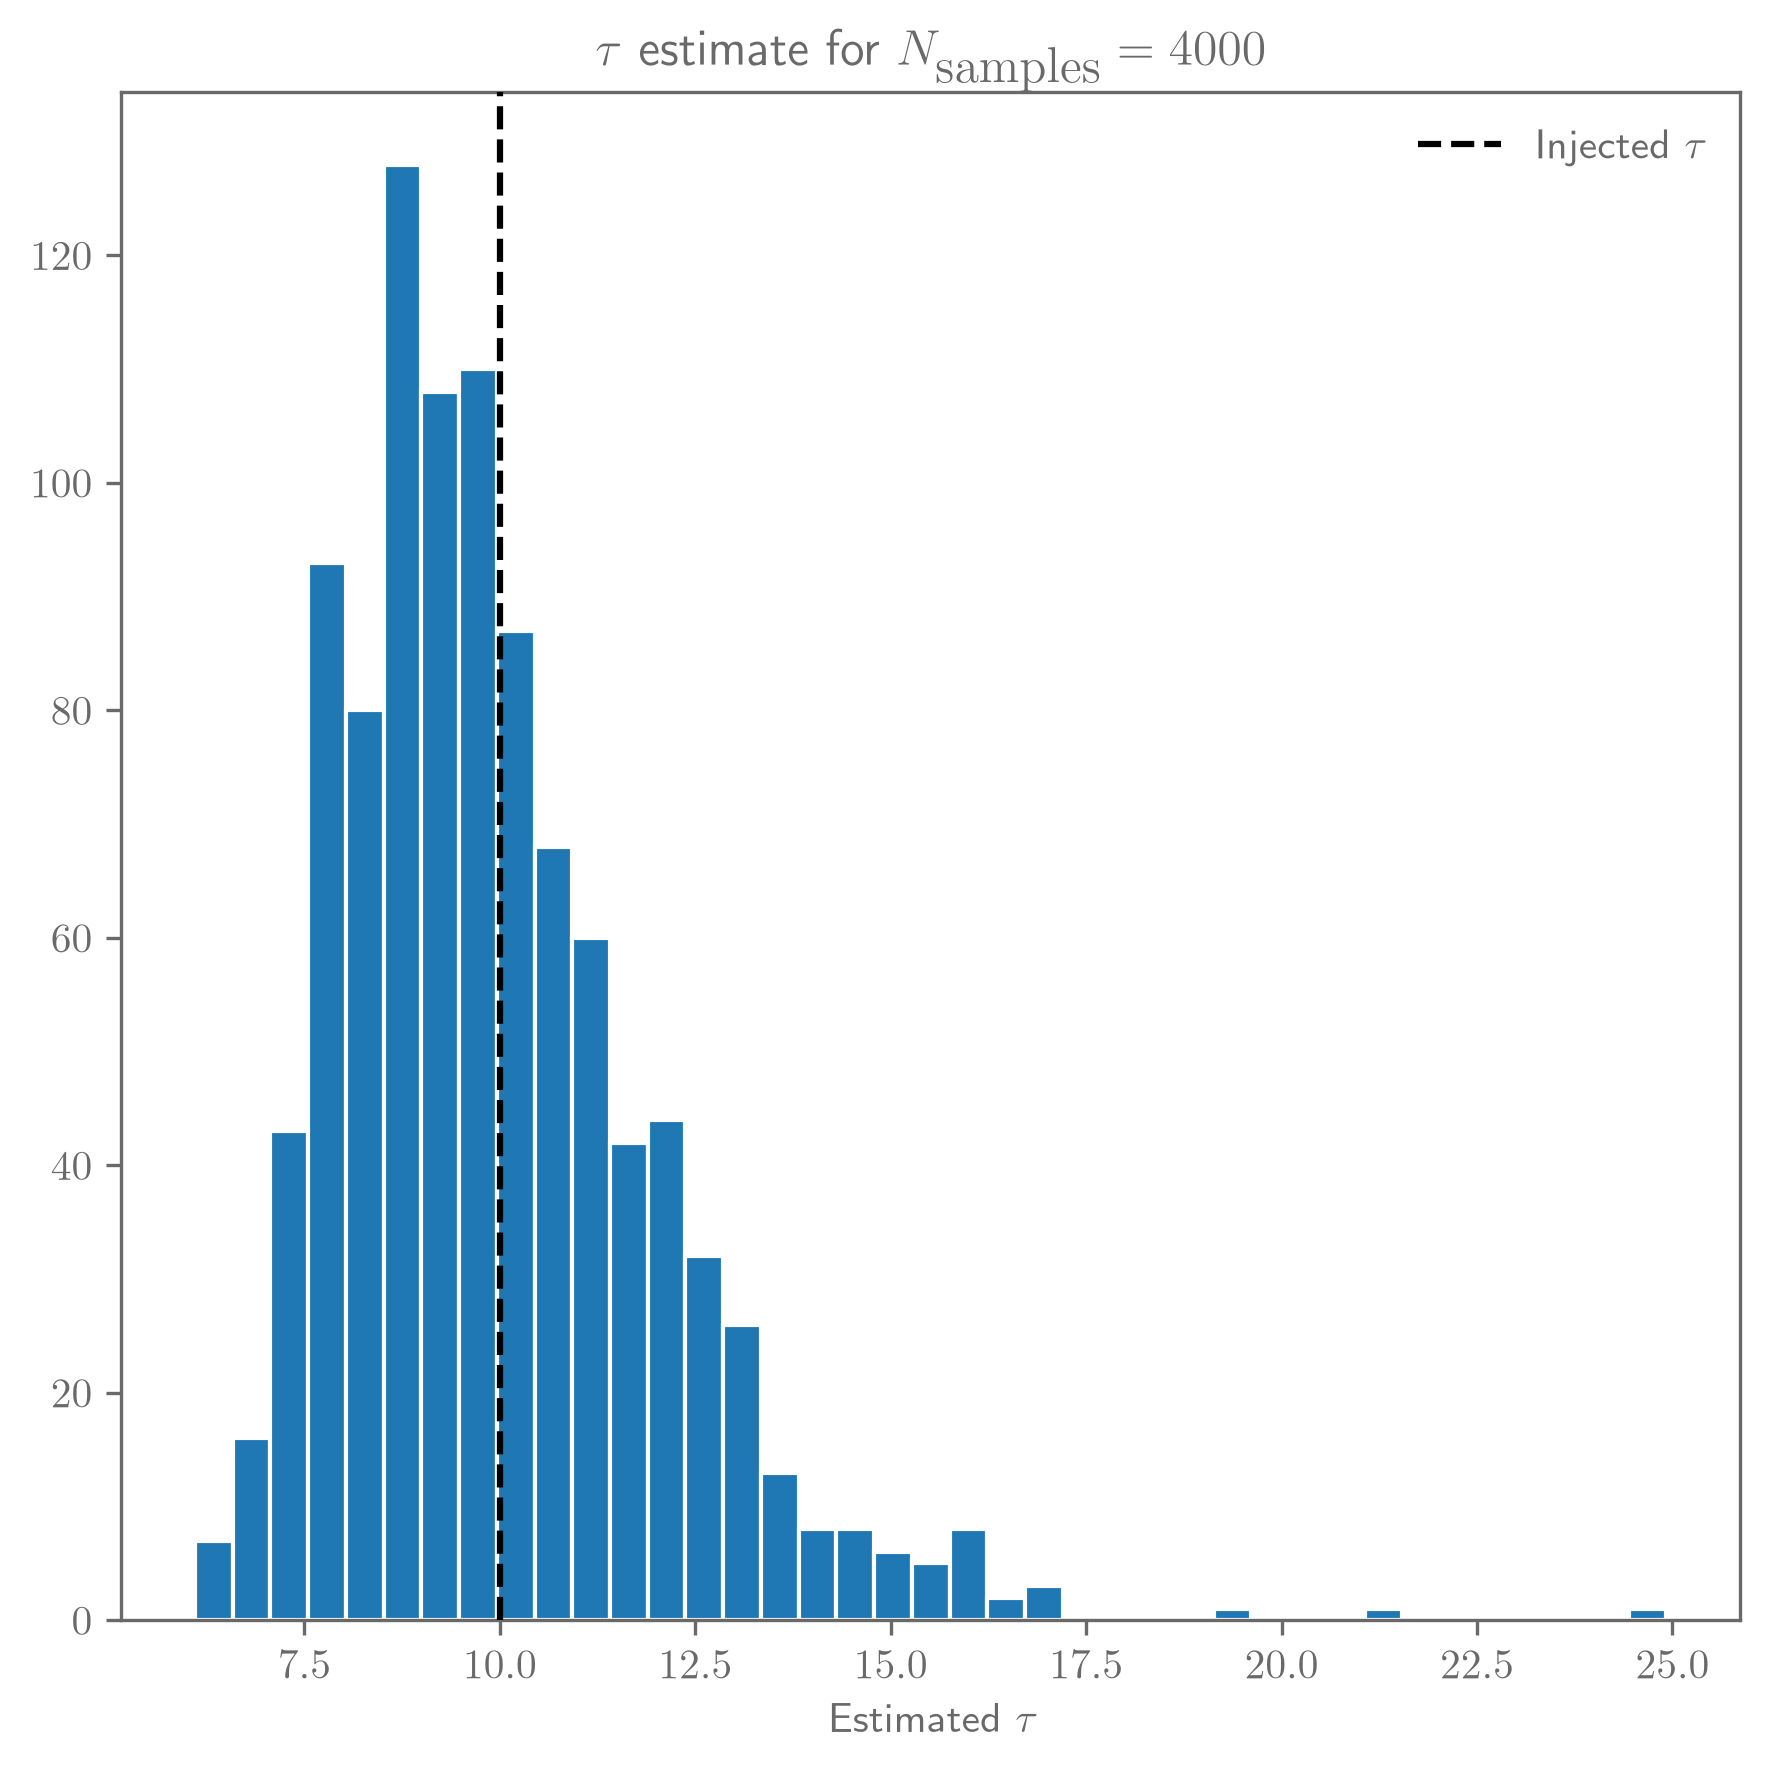

In [7]:
plt.figure(figsize=(6, 6))
plt.hist(taus, bins='auto', edgecolor='w')
ax = plt.gca()
ax.axvline(tau_autocorr, c='k', ls='--', zorder=100, label='Injected $\\tau$')
plt.xlabel("Estimated $\\tau$")
plt.title(f'$\\tau$ estimate for $N_{{\\textrm{{samples}}}}={Nsamples}$')
plt.legend()
plt.tight_layout()
if savefigs:
    plt.savefig(figdir / "tau_estimates.pdf")
plt.show()

## Exercise 1: Problem statement

* For a given $N_{samples}$ create many simulated chains with both correlated and iid samples.
* * For each chain, look at the mean.
* **How does *the variance of the means* compare between the correlated and iid samples? Repeat this again for different $N_{samples}$.**
* **How do these variances scale with $N_{samples}$? What about $n_{eff}$?**

Use the `ar1(N, rng, nchains=1)` function, defined above, to simulate data, where "N" is the number of samples per chain, "rng" is the random number generator from above, and "nchains" gives you the total number of chains to simulate of that length.

**important** when calling `integrated_time` make sure to use `quiet=True` and `tol=0` otherwise you may get a ton of error messages. 

In [8]:
tau_true = tau_autocorr

Ns = np.unique(np.logspace(2, 4.5, 12).astype(int))
nchains = 500

res = {k: [] for k in ["var_mean_corr", "var_mean_iid", "mean_var_corr", "tau_med"]}
for N in Ns:
    x = ar1(N, tau_autocorr, rng, nchains)                         # (N, nchains) correlated
    y = rng.standard_normal((N, nchains))            # (N, nchains) iid
    taus = [integrated_time(x[:, j], quiet=True, tol=0)[0] for j in range(nchains)]
    res["var_mean_corr"].append(x.mean(0).var(ddof=1))
    res["var_mean_iid"].append(y.mean(0).var(ddof=1))
    res["mean_var_corr"].append(x.var(0, ddof=1).mean())
    res["tau_med"].append(np.median(taus))
res = {k: np.array(v) for k, v in res.items()}

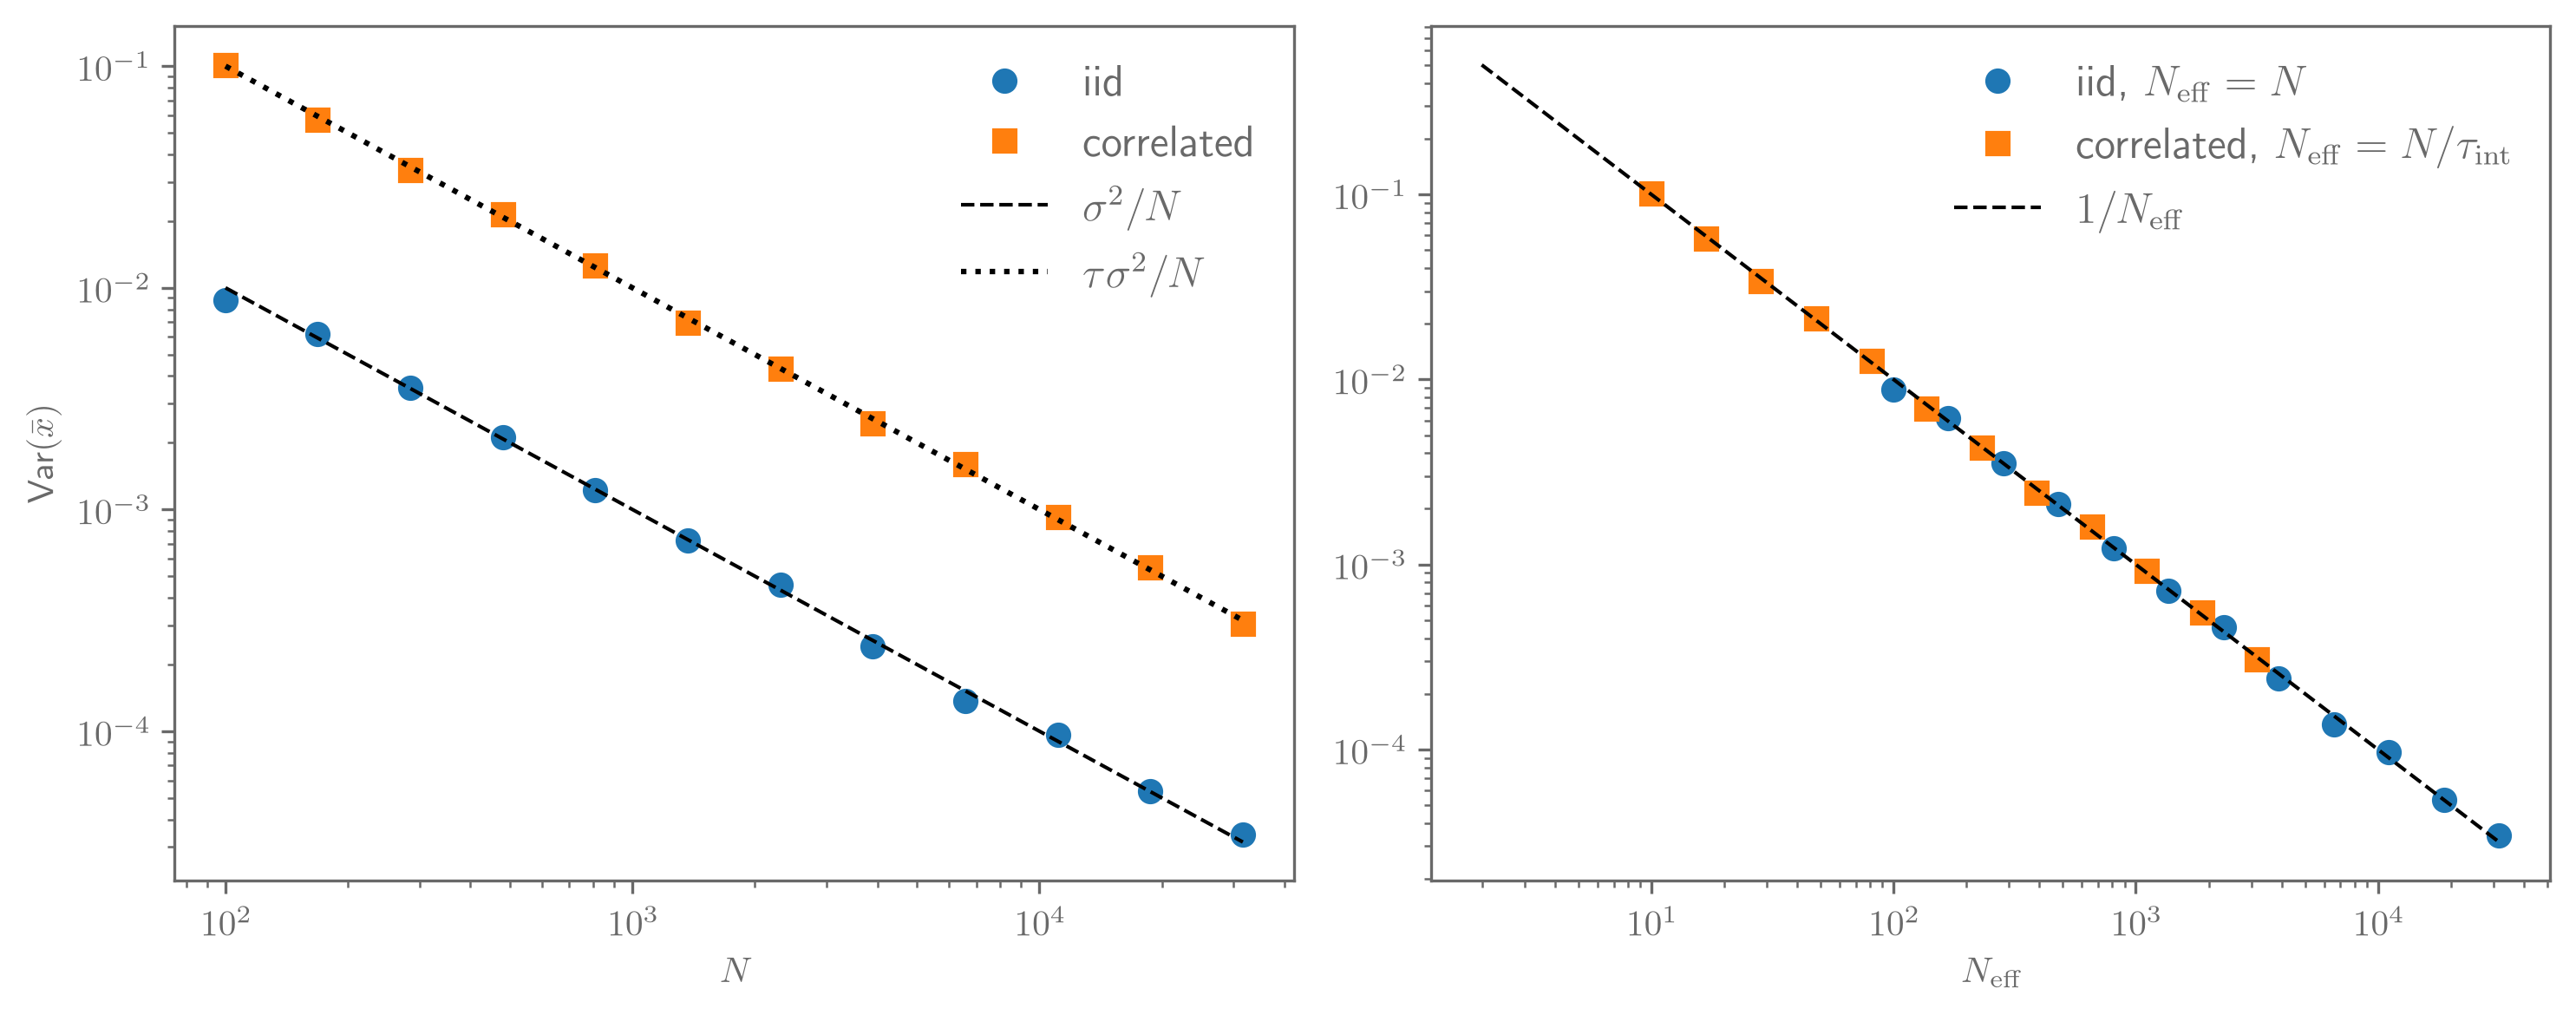

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].loglog(Ns, res["var_mean_iid"], "o", label="iid")
ax[0].loglog(Ns, res["var_mean_corr"], "s", label="correlated")
ax[0].loglog(Ns, 1 / Ns, "k--", label=r"$\sigma^2/N$", lw=1)
ax[0].loglog(Ns, tau_true / Ns, "k:", label=r"$\tau\sigma^2/N$")
ax[0].set(xlabel="$N$", ylabel=r"Var$(\bar x)$");
ax[0].legend(fontsize=12)

ax[1].loglog(Ns, res["var_mean_iid"], "o", label=r"iid, $N_\mathrm{eff}=N$")
ax[1].loglog(Ns / tau_true, res["var_mean_corr"], "s",
             label=r"correlated, $N_\mathrm{eff}=N/\tau_\mathrm{int}$")
xx = np.logspace(0.3, 4.5)
ax[1].loglog(xx, 1 / xx, "k--", label=r"$1/N_\mathrm{eff}$", lw=1)
ax[1].set(xlabel=r"$N_\mathrm{eff}$"); ax[1].legend(fontsize=12)
fig.tight_layout()
if savefigs:
    fig.savefig(figdir / "estimator_variance.pdf")

### Use $\tau_{est}$ instead of $\tau_{true}$

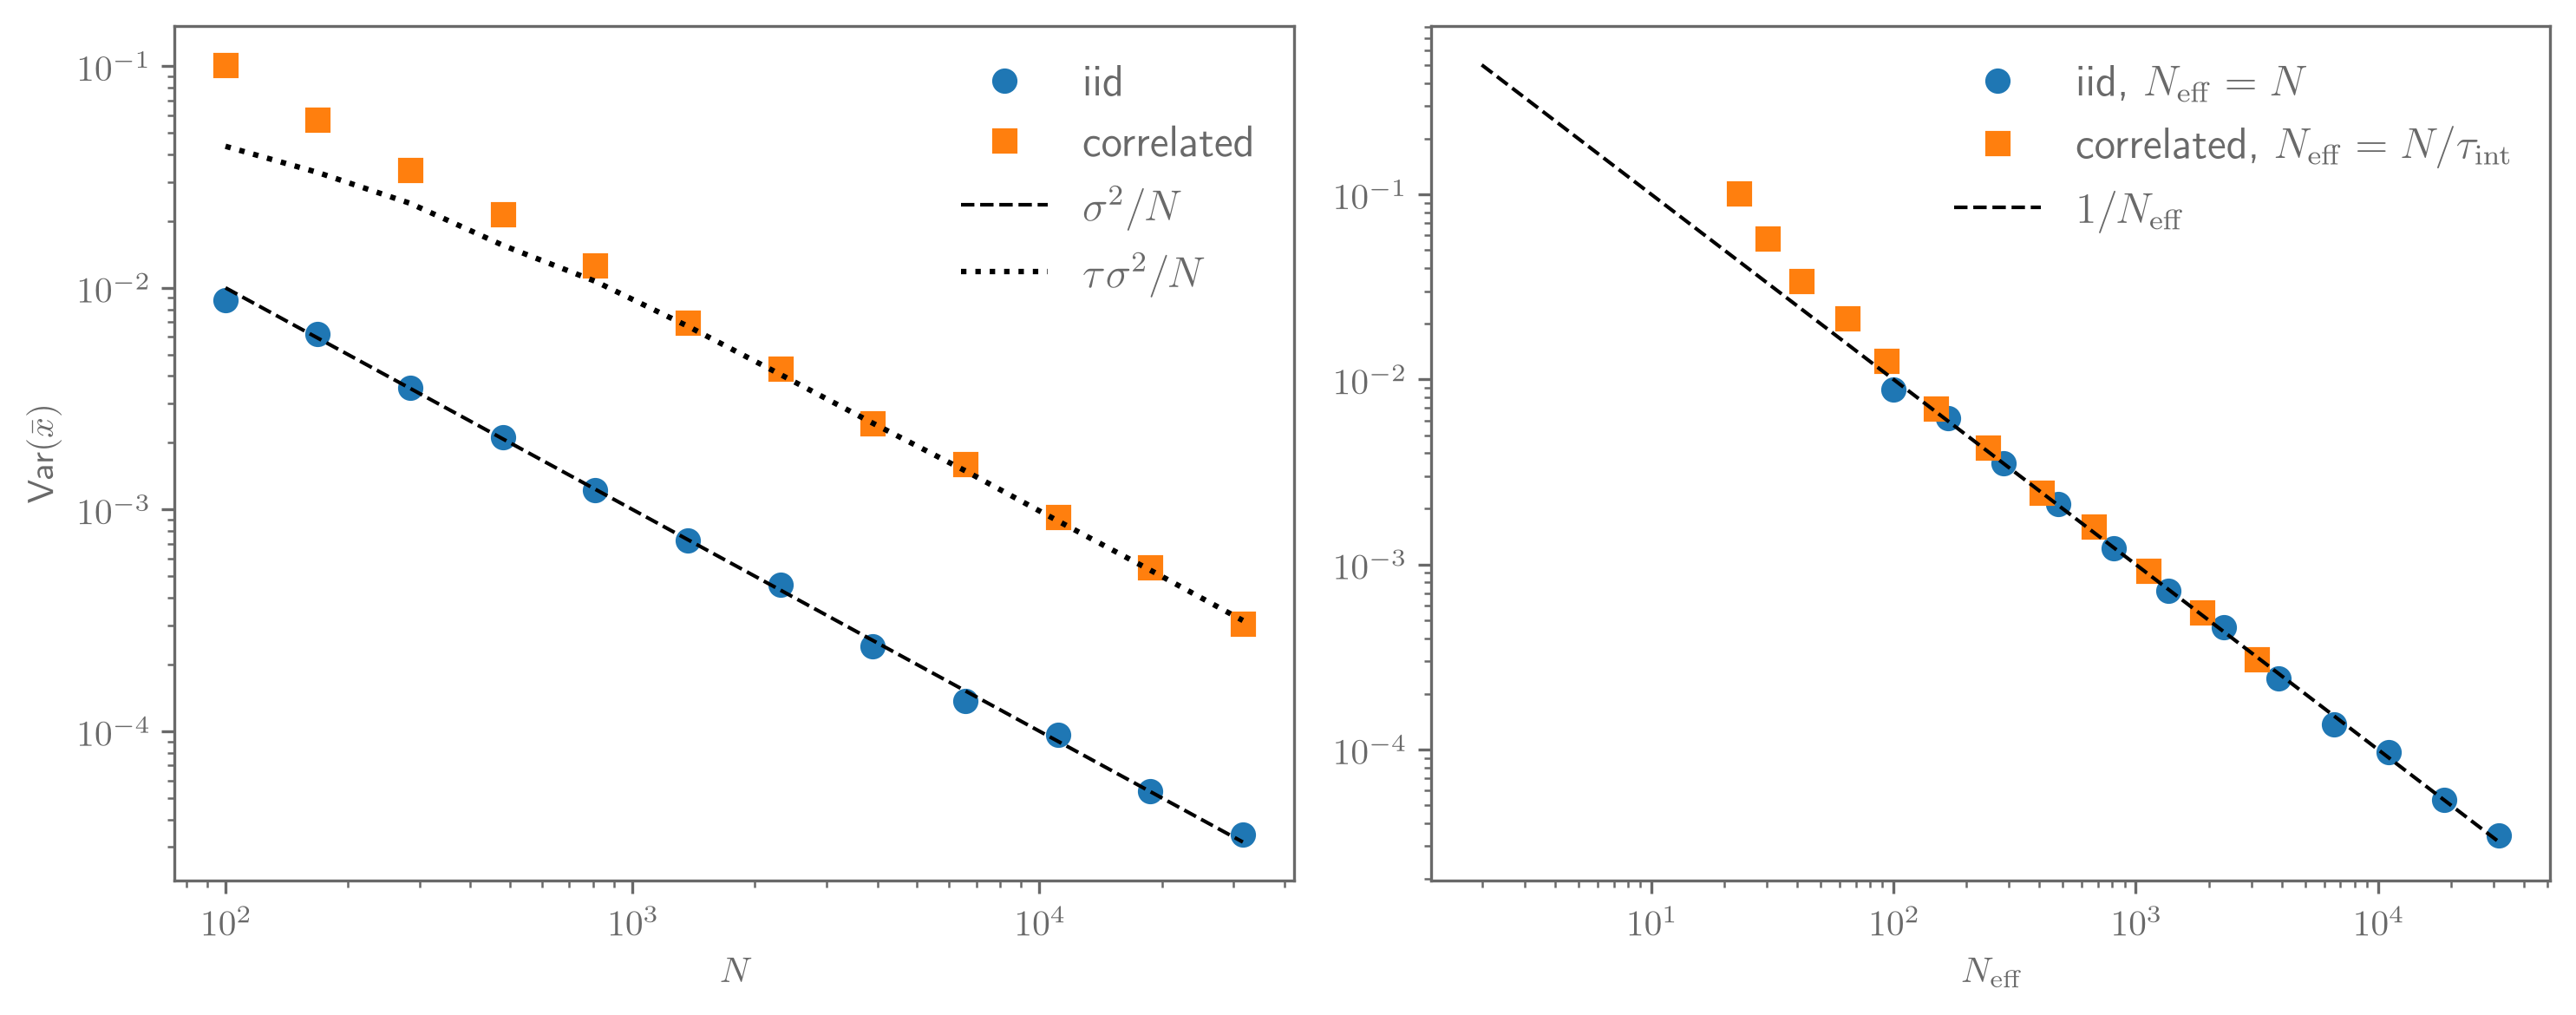

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].loglog(Ns, res["var_mean_iid"], "o", label="iid")
ax[0].loglog(Ns, res["var_mean_corr"], "s", label="correlated")
ax[0].loglog(Ns, 1 / Ns, "k--", label=r"$\sigma^2/N$", lw=1)
ax[0].loglog(Ns, res["tau_med"] / Ns, "k:", label=r"$\tau\sigma^2/N$") # replace true tau with median across chains
ax[0].set(xlabel="$N$", ylabel=r"Var$(\bar x)$");
ax[0].legend(fontsize=12)

ax[1].loglog(Ns, res["var_mean_iid"], "o", label=r"iid, $N_\mathrm{eff}=N$")
ax[1].loglog(Ns / res["tau_med"], res["var_mean_corr"], "s",
             label=r"correlated, $N_\mathrm{eff}=N/\tau_\mathrm{int}$") # replace true atu with median across chains
xx = np.logspace(0.3, 4.5)
ax[1].loglog(xx, 1 / xx, "k--", label=r"$1/N_\mathrm{eff}$", lw=1)
ax[1].set(xlabel=r"$N_\mathrm{eff}$"); ax[1].legend(fontsize=12)
fig.tight_layout()
if savefigs:
    fig.savefig(figdir / "estimator_variance_tau_estimated.pdf")

# Exercise 2 -- confidence intervals

## Calculate the 90% equal tail interval on the iid samples

In [11]:
fifth, fiftieth, ninety_fifth = np.percentile(iid_samples, [5, 50, 95])

In [12]:
print(fifth, fiftieth, ninety_fifth)

-1.6510364513479159 0.005428436070845801 1.6611882026650198


## Use arviz to calculate a highest density interval

Use [arviz.hdi](https://python.arviz.org/en/v0.19.0/api/generated/arviz.hdi.html)

In [13]:
hdi = arviz.hdi(iid_samples, prob=.90)
print(hdi)

[-1.64655383  1.66622616]


## Repeat for a multi-modal distribution
`hdi_bimodal = arviz.hdi(bimodal_samples, prob=.90,max_modes=2, method='multimodal')`
where you create the bimodal samples yourself. 

In [14]:
bimodal_samples = np.r_[np.random.randn(Nsamples), np.random.randn(Nsamples) + 10]
hdi_bimodal = arviz.hdi(bimodal_samples, prob=.90,max_modes=2, method='multimodal')
# note that this will produce two intervals now because the hdi is disjoint!
print(hdi_bimodal)
fifth_bm, fiftieth_bm, ninety_fifth_bm = np.percentile(bimodal_samples, [5, 50, 95])

[[-1.65832464  1.68414453]
 [ 8.33314235 11.71155205]]


## Compare hdi and equal tail for the uni-modal and bimodal cases (make a plot)

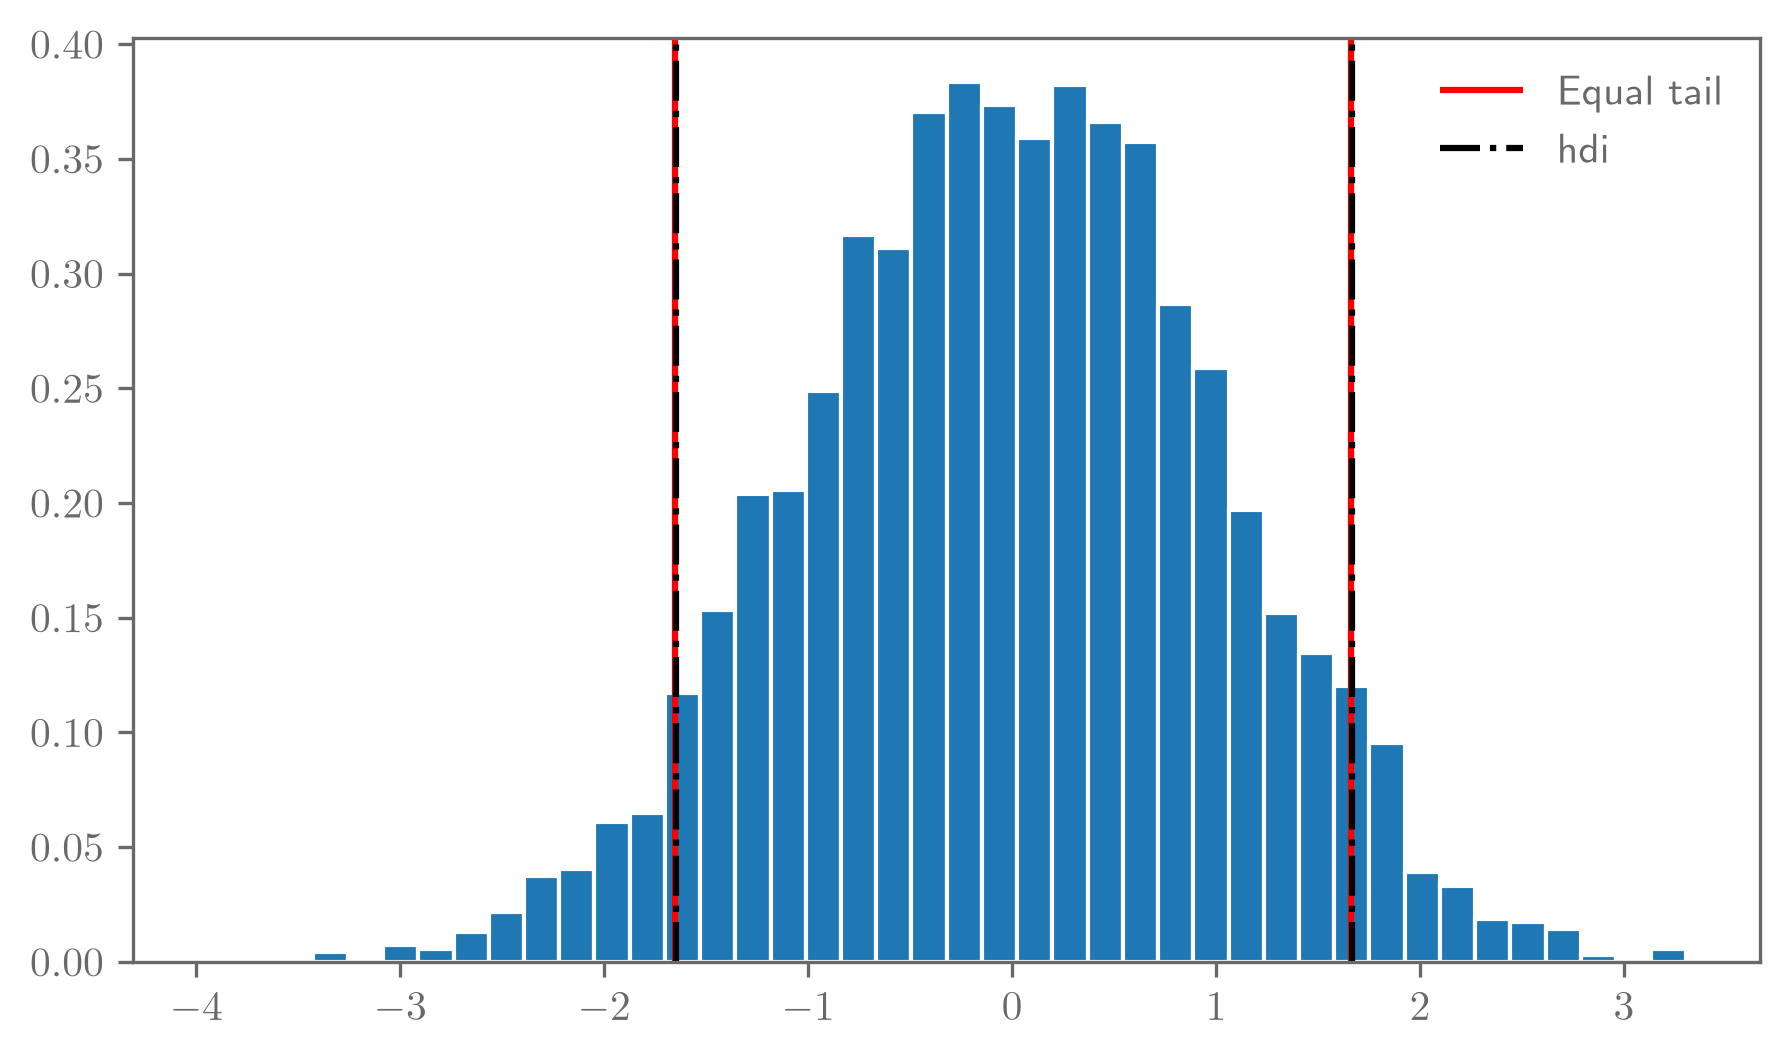

In [15]:
plt.hist(iid_samples, bins='auto', edgecolor='w', density=True)
ax = plt.gca()
ax.vlines([fifth, ninety_fifth], ymin=0, ymax=1, color='r', label='Equal tail', transform=ax.get_xaxis_transform())
ax.vlines(hdi, ymin=0, ymax=1, color='k', ls='-.', label='hdi', transform=ax.get_xaxis_transform())
plt.legend()
plt.show()

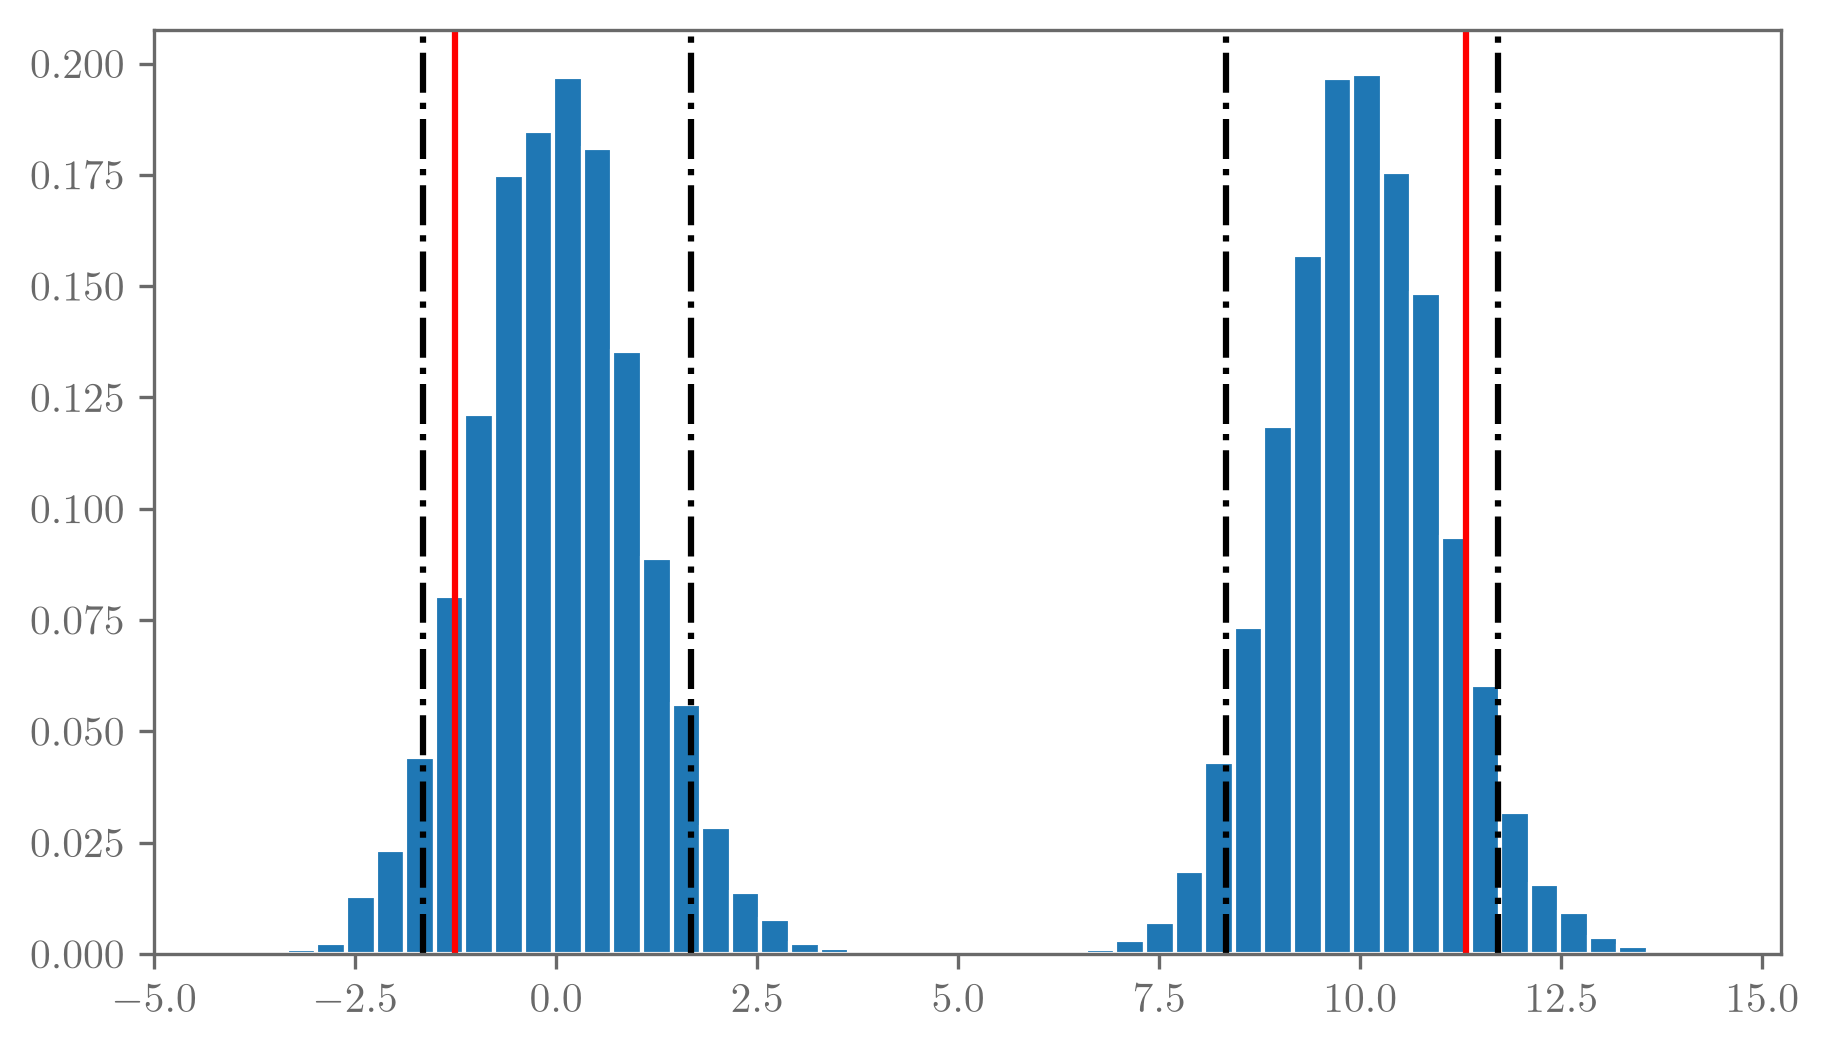

In [16]:

plt.hist(bimodal_samples, edgecolor='w', density=True, bins=50)
ax = plt.gca()
ax.vlines(hdi_bimodal, ymin=0, ymax=1, color='k', ls='-.', label='hdi', transform=ax.get_xaxis_transform())
ax.vlines([fifth_bm, ninety_fifth_bm], ymin=0, ymax=1, color='r', label='Equal tail', transform=ax.get_xaxis_transform())
plt.show()

# Exercise 3 -- $\chi^2$

## Example first

In [17]:
from bayesian_stats_course_tools.analyse import plot_data, analyse_data

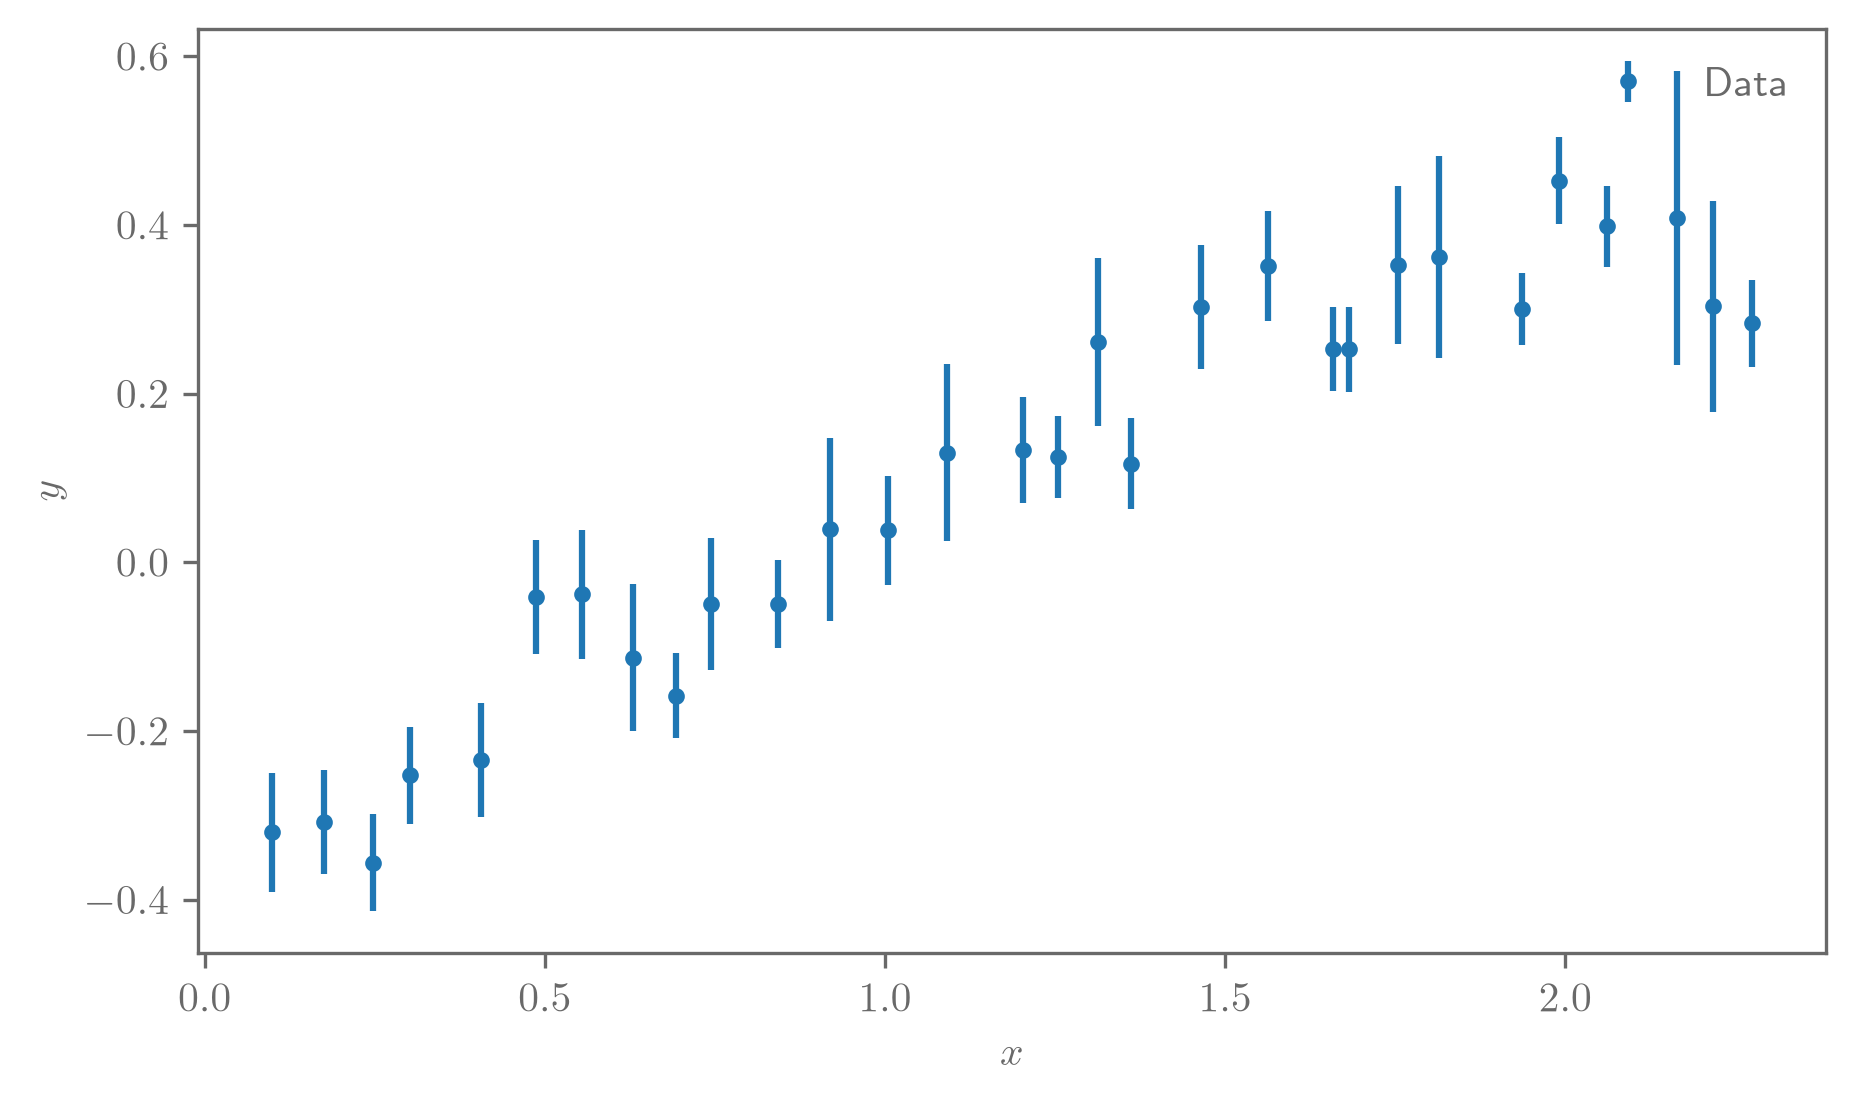

In [18]:
# let's load our data
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_2.txt", unpack=True)
a_true, b_true, c_true,  = -0.15, 0.7, -0.45

plot_data(x, y, y_err, );

### Gaussian likelihood, define models, etc. 

In [19]:
def make_gaussian_likelihood_components(model, log_prior):
    """Create the log_likelihood, log_posterior, predict functions from a
    model and log_prior"""
    def log_likelihood(y, theta, x, sigma_y):
        # the gaussian likelihood

        # 
        prediction = model(theta, x)

        return (
            -0.5 * np.sum((y - prediction)**2/sigma_y**2)    # Exponent
            -0.5 * np.sum(np.log(2*np.pi*sigma_y**2))        # Normalisation
        )
    
    def log_posterior(theta, x, sigma_y, y):
        # the full posterior is likelihood + prior
        return log_likelihood(y, theta, x, sigma_y) + log_prior(theta)
    
    def predict(theta, x, sigma_y):
        # for posterior predictive tests
        mu = model(theta, x)
        return np.random.normal(loc=mu, scale=sigma_y)
    
    return log_likelihood, log_posterior, predict

### define models

In [20]:
def linear_model(theta, x):
    m, b = theta
    return m*x + b

def log_prior_linear_model(theta):
    m, b = theta
    # Unnormalised uniform prior m\simU(-2, 2), b \sim U(-3, 3)
    if -2 < m < 2 and -3 < b < 3:
        return 0
    else:
        return -np.inf

log_likelihood_lin, log_posterior_lin, predict_lin = \
    make_gaussian_likelihood_components(
        linear_model, log_prior_linear_model
    )

In [21]:
# quadratic modelss
def quadratic_model(theta, x):
    a, b, c = theta
    return a*x**2 + b*x + c

def log_prior_quadratic_model(theta):
    a, b, c = theta
    # Unnormalised uniform prior m\simU(-2, 2), b \sim U(-3, 3)
    if -1 < a < 1 and -2 < b < 2 and -3 < c < 3:
        return 0
    else:
        return -np.inf

log_likelihood_quad, log_posterior_quad, predict_quad = \
    make_gaussian_likelihood_components(
        quadratic_model, log_prior_quadratic_model
    )

### analyze data

In [22]:
results_linear = analyse_data(
    data=dict(x=x, y=y, y_err=y_err),
    log_posterior_fn=log_posterior_lin,
    model_fn=linear_model,
    predict_fn=predict_lin,
    param_names=["m", "b"],
    theta_init=[1, 0],
    plot=False
)

results_quadratic = analyse_data(
    data=dict(x=x, y=y, y_err=y_err),
    log_posterior_fn=log_posterior_quad,
    model_fn=quadratic_model,
    predict_fn=predict_quad,
    param_names=["a", "m", "b"],
    theta_init=[0.1, 1, 0],
    plot=False
)

MAP results
m_MAP = 0.34908377290541787
b_MAP = -0.33212704099855833


/Users/pmeyers/miniforge3/envs/stats_course/lib/python3.14/site-packages/scipy/optimize/_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]
100%|█████████████████████████████████████████████████████████████| 5000/5000 [00:00<00:00, 11127.92it/s]
/Users/pmeyers/miniforge3/envs/stats_course/lib/python3.14/site-packages/scipy/optimize/_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]
/Users/pmeyers/miniforge3/envs/stats_course/lib/python3.14/site-packages/scipy/optimize/_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


Auto-correlation time of chain:
m = 26.4
b = 29.8
Posterior results (mean±std)
m = 0.35±0.017
b = -0.33±0.024
MAP results
a_MAP = -0.10547710642388063
m_MAP = 0.5990527808099008
b_MAP = -0.4340001193160153


100%|██████████████████████████████████████████████████████████████| 5000/5000 [00:00<00:00, 9284.38it/s]

Auto-correlation time of chain:
a = 84.6
m = 62.0
b = 63.9
Posterior results (mean±std)
a = -0.11±0.031
m = 0.6±0.075
b = -0.43±0.039


In [23]:
# ??analyze_data # will print the full function for analyze_data

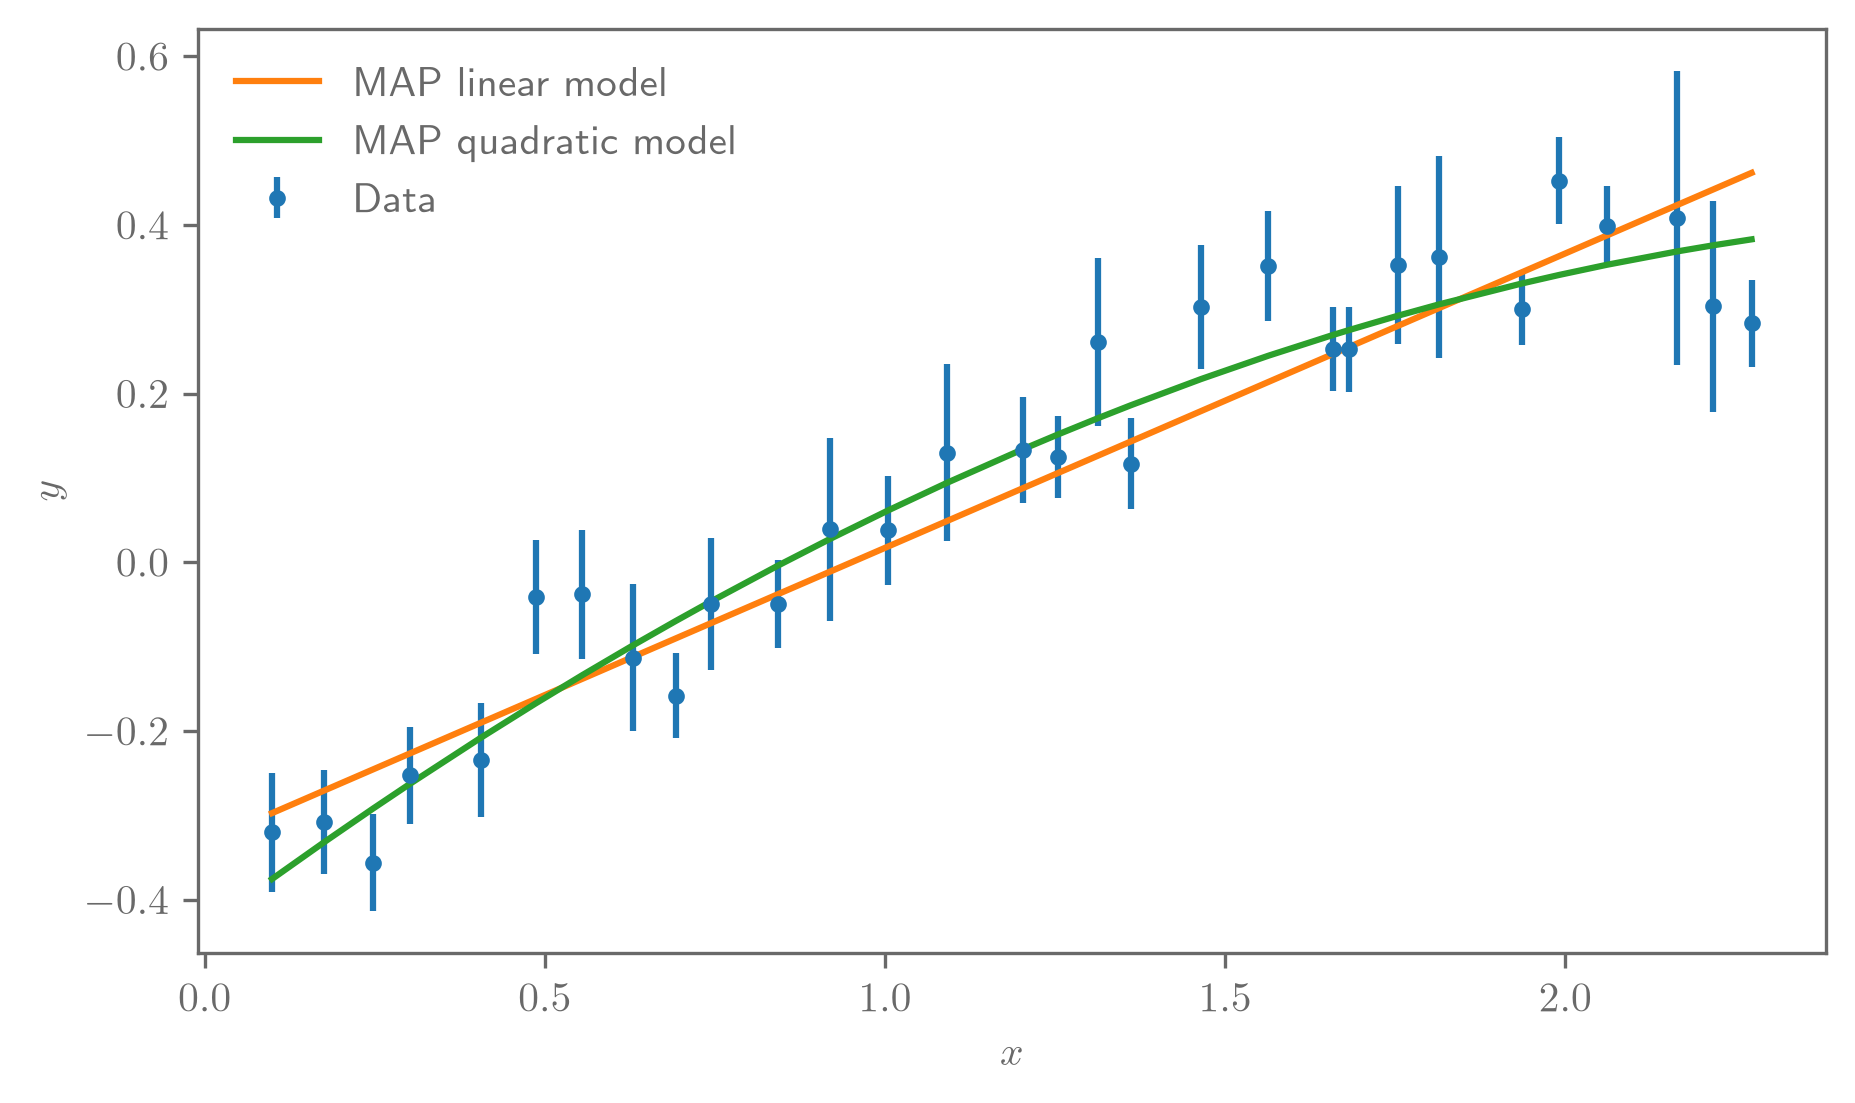

In [24]:
plot_data(
    x, y, y_err,
    models=[
        dict(x=x, y=linear_model(results_linear["MAP"], x), style=dict(label="MAP linear model")),
        dict(x=x, y=quadratic_model(results_quadratic["MAP"], x), style=dict(label="MAP quadratic model"))
    ]
);

### calculate $\chi^2$ on MAP parameters

In [25]:
def chi_squared(y, sigma_y, mu):
    return np.sum((y - mu)**2/sigma_y**2)

chi_squared_linear = chi_squared(
    y, y_err,
    mu=linear_model(results_linear["MAP"], x)
)
chi_squared_quadratic = chi_squared(
    y, y_err,
    mu=quadratic_model(results_quadratic["MAP"], x)
)

In [26]:
n_data = len(y)
n_param_lin = 2
n_param_quad = 3

PTE_lin = scipy.stats.chi2(df=n_data - n_param_lin).sf(chi_squared_linear)
PTE_quad = scipy.stats.chi2(df=n_data - n_param_quad).sf(chi_squared_quadratic)

print(f"Linear: χ²={chi_squared_linear:.1f}, "
      f"ndof={n_data}-{n_param_lin}, PTE={PTE_lin:.3f}")

print(f"Quadratic: χ²={chi_squared_quadratic:.1f}, "
      f"ndof={n_data}-{n_param_quad}, PTE={PTE_quad:.3f}")

Linear: χ²=40.8, ndof=30-2, PTE=0.056
Quadratic: χ²=29.3, ndof=30-3, PTE=0.347


### What about when we have posteriors?

## Exercise 3 -- Posterior predictive p-value problems

### **Calculate $p_B$ from the lecture notes now using our posteriors.** 

`results_quad` contains posterior predictive draws already in it. You can use these if you'd like. These represent a list of draws from $p(y | \theta^s)$ where $s$ represents the step in the chain. 

To help with some conventions from results from earlier in the notebook:

If you have run the notebook to this point, then you can use `results_linear['chain']` to get values of $\theta$, `predict_lin` or `predict_quad` to draw from the posterior predictive, `linear_model` or `quadratic_model` to calculate the **model** predictive (needed for the $\chi^2$). 

### **Try another statistic**: how many times does the sign of the residual change? If we fit a line to quadratic data, then we'd expect there to be a chunk of residuals that are all positive, in a row, for example. 

In [27]:
# random draws
n_draws = 500
random_draw_integers = np.random.randint(0, high=results_linear['chain'].shape[0], size=n_draws)
N_exceed_lin = 0
linear_T_reps = []
linear_T_reals = []
for ii in range(n_draws):
    # draw theta from p(theta | y)
    theta_linear = results_linear['chain'][random_draw_integers[ii]]

    # posterior predictive draw
    yrep_linear = predict_lin(theta_linear, x, y_err)

    # model predictive
    mu = linear_model(theta_linear, x)

    # calculate T on replicated data
    T_rep_linear = chi_squared(yrep_linear, y_err, mu)
    linear_T_reps.append(T_rep_linear)
    # calculate T on real data
    T_real_linear = chi_squared(y, y_err, mu)
    linear_T_reals.append(T_real_linear)
    if T_rep_linear >= T_real_linear:
        N_exceed_lin += 1


In [28]:
# random draws
n_draws = 500
random_draw_integers = np.random.randint(0, high=results_quadratic['chain'].shape[0], size=n_draws)
N_exceed_quad = 0
quad_T_reps = []
quad_T_reals = []
for ii in range(n_draws):
    # draw theta from p(theta | y)
    theta_quad = results_quadratic['chain'][random_draw_integers[ii]]

    # posterior predictive draw
    yrep_quad = predict_quad(theta_quad, x, y_err)

    # model predictive
    mu = quadratic_model(theta_quad, x)

    # calculate T on replicated data
    T_rep_quad = chi_squared(yrep_quad, y_err, mu)
    quad_T_reps.append(T_rep_quad)
    # calculate T on real data
    T_real_quad = chi_squared(y, y_err, mu)
    quad_T_reals.append(T_real_quad)
    if T_rep_quad >= T_real_quad:
        N_exceed_quad += 1


p_b quad model = 0.354
p_b linear = 0.08


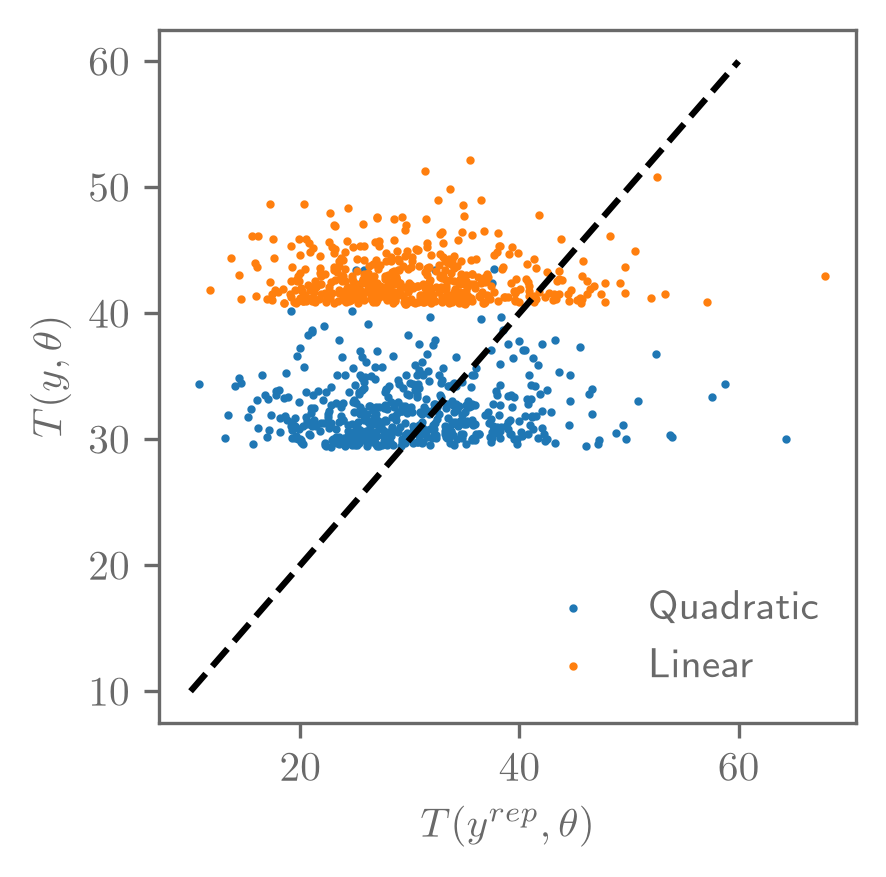

In [29]:
print(f"p_b quad model = {N_exceed_quad / n_draws}")
print(f"p_b linear = {N_exceed_lin / n_draws}")
plt.figure(figsize=(3, 3))
plt.scatter(quad_T_reps, quad_T_reals, s=1, label='Quadratic')
plt.scatter(linear_T_reps, linear_T_reals, s=1, label='Linear')
plt.xlabel("$T(y^{rep}, \\theta)$")
plt.ylabel("$T(y, \\theta)$")
plt.legend()
plt.plot([10, 60], [10, 60], c='k', ls='--')
plt.show()

### Sign change statistic test

We find a posterior predictive p-value of around 0.9 for the linear model (again, extremes that are high *or* low are interesting in these cases)

In [30]:
def sign_change(y, mu):
    r = y - mu
    # get the signs
    r_signs = np.sign(r)
    # get diffs
    r_changed = np.abs(r_signs[:-1] - r_signs[1:]) # zero if there's no change, 1 if there is a sign change
    num_changed = np.sum(r_changed)
    return num_changed

In [31]:
# random draws
n_draws = 1000
random_draw_integers = np.random.randint(0, high=results_linear['chain'].shape[0], size=n_draws)
N_exceed_lin = 0
linear_T_reps = []
linear_T_reals = []
for ii in range(n_draws):
    # draw theta from p(theta | y)
    theta_linear = results_linear['chain'][random_draw_integers[ii]]

    # posterior predictive draw
    yrep_linear = predict_lin(theta_linear, x, y_err)

    # model predictive
    mu = linear_model(theta_linear, x)

    # calculate T on replicated data
    T_rep_linear = sign_change(yrep_linear, mu)
    linear_T_reps.append(T_rep_linear)
    # calculate T on real data
    T_real_linear = sign_change(y, mu)
    linear_T_reals.append(T_real_linear)
    if T_rep_linear >= T_real_linear:
        N_exceed_lin += 1


# random draws
n_draws = 1000
random_draw_integers = np.random.randint(0, high=results_quadratic['chain'].shape[0], size=n_draws)
N_exceed_quad = 0
quad_T_reps = []
quad_T_reals = []
for ii in range(n_draws):
    # draw theta from p(theta | y)
    theta_quad = results_quadratic['chain'][random_draw_integers[ii]]

    # posterior predictive draw
    yrep_quad = predict_quad(theta_quad, x, y_err)

    # model predictive
    mu = quadratic_model(theta_quad, x)

    # calculate T on replicated data
    T_rep_quad = sign_change(yrep_quad, mu)
    quad_T_reps.append(T_rep_quad)
    # calculate T on real data
    T_real_quad = sign_change(y, mu)
    quad_T_reals.append(T_real_quad)
    if T_rep_quad >= T_real_quad:
        N_exceed_quad += 1


p_b quad model = 0.4
p_b linear = 0.885


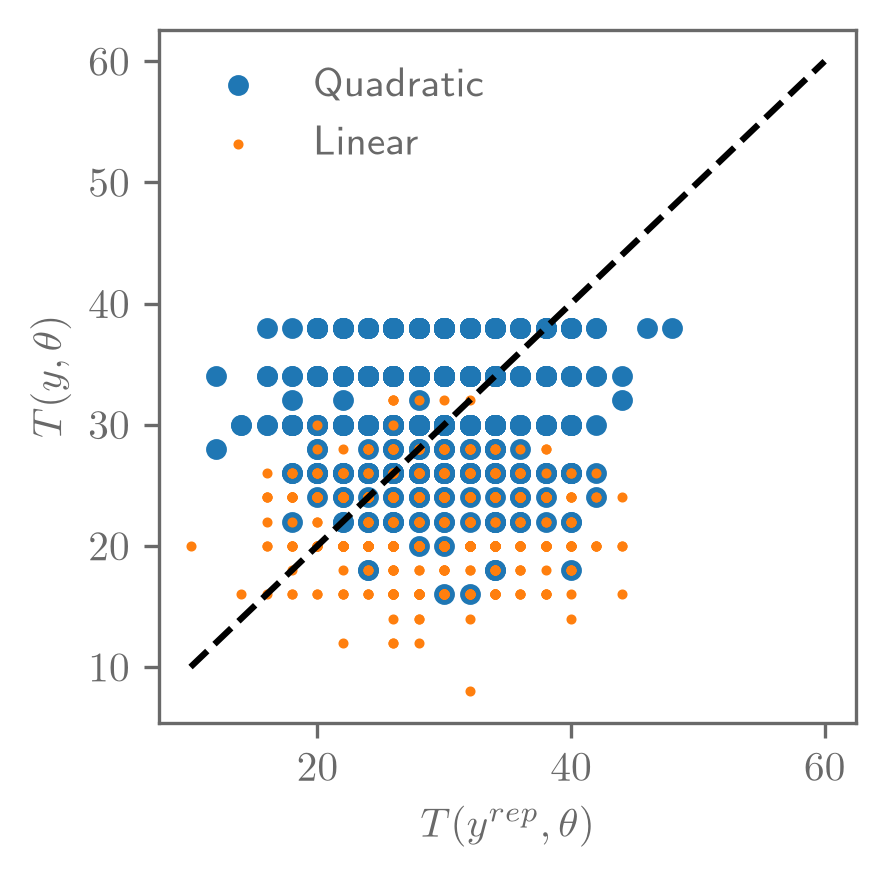

In [32]:
print(f"p_b quad model = {N_exceed_quad / n_draws}")
print(f"p_b linear = {N_exceed_lin / n_draws}")
plt.figure(figsize=(3, 3))
plt.scatter(quad_T_reps, quad_T_reals, s=16, label='Quadratic')
plt.scatter(linear_T_reps, linear_T_reals, s=2, label='Linear')
plt.xlabel("$T(y^{rep}, \\theta)$")
plt.ylabel("$T(y, \\theta)$")
plt.legend()
plt.plot([10, 60], [10, 60], c='k', ls='--')
plt.show()